
# Анализ данных маркетплейса Olist


In [3]:
pip install pandas sqlalchemy psycopg matplotlib seaborn python-dotenv jupyter

Note: you may need to restart the kernel to use updated packages.


### Подготовка и загрузка данных

In [ ]:
import os

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from dotenv import load_dotenv
from sqlalchemy import create_engine

load_dotenv()

DATABASE_URL = os.getenv("DATABASE_URL")

engine = create_engine(DATABASE_URL)

Подключение к PostgreSQL настроено


In [6]:
query = """
SELECT
    fo.order_id,
    dc.customer_unique_id,
    fo.order_purchase_timestamp,
    fo.order_status,
    fo.total_order_amount,
    fo.delivery_days,
    fo.days_late,
    fo.is_delayed,
    fo.review_score
FROM dwh.fact_orders fo
JOIN dwh.dim_customers dc
    ON fo.customer_id = dc.customer_id
"""

orders = pd.read_sql(query, engine)

orders.head()
orders.info()
orders.describe()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   order_id                  99441 non-null  str           
 1   customer_unique_id        99441 non-null  str           
 2   order_purchase_timestamp  99441 non-null  datetime64[us]
 3   order_status              99441 non-null  str           
 4   total_order_amount        99441 non-null  float64       
 5   delivery_days             96476 non-null  float64       
 6   days_late                 96476 non-null  float64       
 7   is_delayed                96476 non-null  object        
 8   review_score              98673 non-null  float64       
dtypes: datetime64[us](1), float64(4), object(1), str(3)
memory usage: 6.8+ MB


,order_purchase_timestamp,total_order_amount,delivery_days,days_late,review_score
count,99441,99441.000000,96476.000000,96476.000000,98673.000000
mean,2017-12-31 08:43:12.776581,136.680481,12.497336,-11.876881,4.086386
min,2016-09-04 21:15:19,0.000000,0.000000,-147.000000,1.000000
25%,2017-09-12 14:46:19,45.000000,7.000000,-17.000000,4.000000
50%,2018-01-18 23:04:36,85.000000,10.000000,-12.000000,5.000000
75%,2018-05-04 15:42:16,149.900000,16.000000,-7.000000,5.000000
max,2018-10-17 17:30:18,13440.000000,210.000000,188.000000,5.000000
std,NaN,210.172081,9.555460,10.183854,1.347618


### Анализ повторных покупок

In [8]:
customer_stats = (
    orders.groupby("customer_unique_id")
    .agg(
        orders_count=("order_id", "nunique")
    )
)

customer_stats["is_repeat"] = customer_stats["orders_count"] > 1

total_customers = len(customer_stats)
repeat_customers = customer_stats["is_repeat"].sum()
repeat_rate = repeat_customers / total_customers * 100

print(f"Всего клиентов: {total_customers}")
print(f"Повторных покупателей: {repeat_customers}")
print(f"Доля повторных покупателей: {repeat_rate:.2f}%")

Всего клиентов: 96096
Повторных покупателей: 2997
Доля повторных покупателей: 3.12%


In [4]:
def delivery_group(x):
    if pd.isna(x):
        return "3. не доставлен"
    return "2. с задержкой" if x else "1. вовремя"

first["delivery"] = first["is_delayed"].apply(delivery_group)

result = first.groupby("delivery")["is_repeat"].agg(customers="count", repeat_customers="sum")
result["repeat_pct"] = (result["repeat_customers"] / result["customers"] * 100).round(2)
result

,customers,repeat_customers,repeat_pct
delivery,,,
1. вовремя,51821,1522,2.94
2. с задержкой,3670,73,1.99
3. не доставлен,1139,31,2.72


### Анализ стоимости заказов

In [10]:
orders["total_order_amount"].describe()

count    99441.000000
mean       136.680481
std        210.172081
min          0.000000
25%         45.000000
50%         85.000000
75%        149.900000
max      13440.000000
Name: total_order_amount, dtype: float64

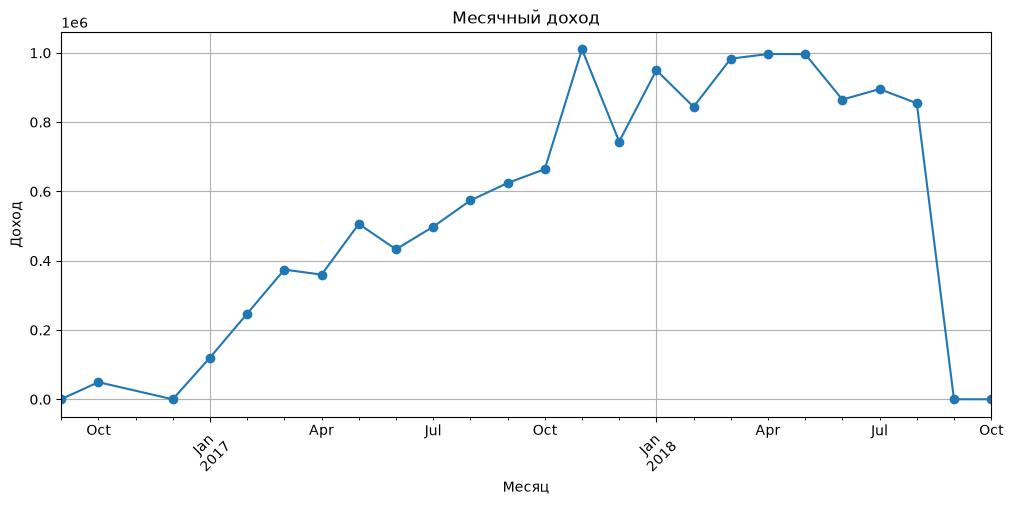

In [14]:
monthly_revenue = (
    orders.groupby(orders["order_purchase_timestamp"].dt.to_period("M"))
    ["total_order_amount"]
    .sum()
)

monthly_revenue.plot(
    kind="line",
    figsize=(12, 5),
    marker="o"
)

plt.title("Месячный доход")
plt.xlabel("Месяц")
plt.ylabel("Доход")
plt.xticks(rotation=45)
plt.grid()
plt.show()

### Анализ доставки

In [12]:
delivery = orders.dropna(subset=["delivery_days", "is_delayed"]).copy()

print(f"Среднее время доставки: {delivery['delivery_days'].mean():.2f} дней")
print(f"Количество заказов с задержкой: {(delivery['is_delayed'] == True).sum()}")
print(f"Количество заказов без задержки: {(delivery['is_delayed'] == False).sum()}")

Среднее время доставки: 12.50 дней
Количество заказов с задержкой: 6535
Количество заказов без задержки: 89941


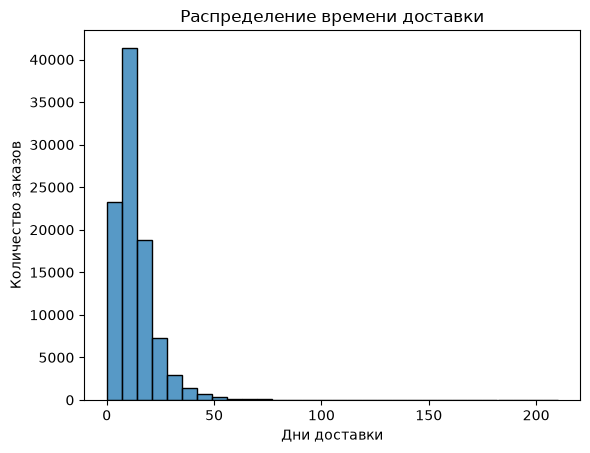

In [15]:
sns.histplot(
    data=delivery,
    x="delivery_days",
    bins=30
)

plt.title("Распределение времени доставки")
plt.xlabel("Дни доставки")
plt.ylabel("Количество заказов")
plt.show()

### Анализ оценок поккупателей

In [16]:
orders["review_score"].value_counts().sort_index()

review_score
1.0    11363
2.0     3131
3.0     8133
4.0    19038
5.0    57008
Name: count, dtype: int64

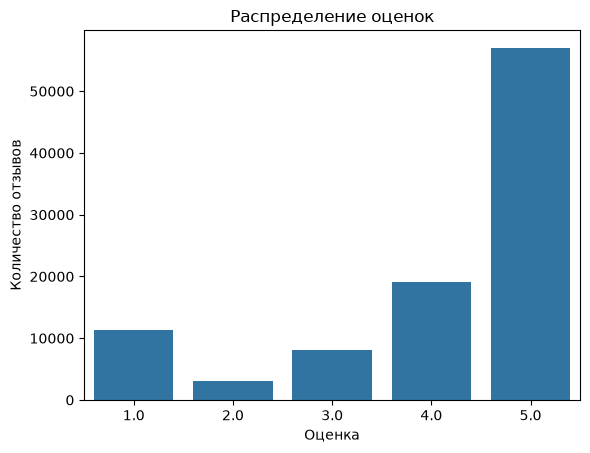

In [21]:
sns.countplot(
    data=orders,
    x="review_score"
)

plt.title("Распределение оценок")
plt.xlabel("Оценка")
plt.ylabel("Количество отзывов")
plt.show()

In [22]:
delivery_reviews = (
    orders.dropna(subset=["review_score", "is_delayed"])
    .groupby("is_delayed")["review_score"]
    .mean()
)

print(delivery_reviews)

is_delayed
False    4.290247
True     2.270605
Name: review_score, dtype: float64


### Анализ повторных покупок по периодам

In [23]:
orders["purchase_month"] = (
    orders["order_purchase_timestamp"].dt.to_period("M")
)

first_purchase = (
    orders.groupby("customer_unique_id")["purchase_month"]
    .min()
    .rename("first_purchase_month")
)

orders = orders.merge(
    first_purchase,
    on="customer_unique_id"
)

orders["customer_type"] = (
    orders["purchase_month"] == orders["first_purchase_month"]
).map({
    True: "New",
    False: "Returning"
})

monthly_customers = pd.pivot_table(
    orders,
    index="purchase_month",
    columns="customer_type",
    values="customer_unique_id",
    aggfunc="nunique",
    fill_value=0
)

monthly_customers.tail()

customer_type,New,Returning
purchase_month,,
2018-06,5940,188
2018-07,6071,159
2018-08,6271,189
2018-09,5,9
2018-10,1,3


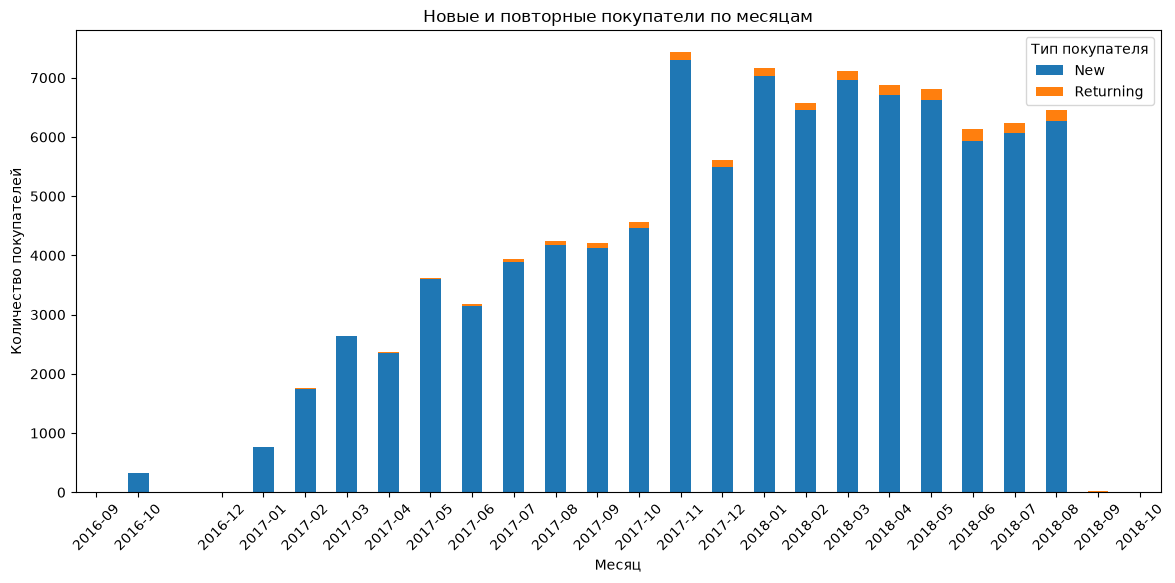

In [25]:
monthly_customers.plot(
    kind="bar",
    stacked=True,
    figsize=(14, 6)
)

plt.title("Новые и повторные покупатели по месяцам")
plt.xlabel("Месяц")
plt.ylabel("Количество покупателей")
plt.xticks(rotation=45)
plt.legend(title="Тип покупателя")
plt.show()